In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Load Dataset
df = pd.read_csv("Titanic-Dataset.csv")

# Display First 5 Rows
print(df.head())

# Dataset Information
print(df.info())

# Missing Values
print(df.isnull().sum())

# Duplicate Records
print("Duplicates:", df.duplicated().sum())

# Dataset Shape
print("Dataset Shape:", df.shape)

   PassengerId  Survived  Pclass  \
0            1         0       3   
1            2         1       1   
2            3         1       3   
3            4         1       1   
4            5         0       3   

                                                Name     Sex   Age  SibSp  \
0                            Braund, Mr. Owen Harris    male  22.0      1   
1  Cumings, Mrs. John Bradley (Florence Briggs Th...  female  38.0      1   
2                             Heikkinen, Miss. Laina  female  26.0      0   
3       Futrelle, Mrs. Jacques Heath (Lily May Peel)  female  35.0      1   
4                           Allen, Mr. William Henry    male  35.0      0   

   Parch            Ticket     Fare Cabin Embarked  
0      0         A/5 21171   7.2500   NaN        S  
1      0          PC 17599  71.2833   C85        C  
2      0  STON/O2. 3101282   7.9250   NaN        S  
3      0            113803  53.1000  C123        S  
4      0            373450   8.0500   NaN        S  
<c

In [4]:
import pandas as pd

df = pd.read_csv("Titanic-Dataset.csv")

print(df.head())
print("Dataset Shape:", df.shape)

   PassengerId  Survived  Pclass  \
0            1         0       3   
1            2         1       1   
2            3         1       3   
3            4         1       1   
4            5         0       3   

                                                Name     Sex   Age  SibSp  \
0                            Braund, Mr. Owen Harris    male  22.0      1   
1  Cumings, Mrs. John Bradley (Florence Briggs Th...  female  38.0      1   
2                             Heikkinen, Miss. Laina  female  26.0      0   
3       Futrelle, Mrs. Jacques Heath (Lily May Peel)  female  35.0      1   
4                           Allen, Mr. William Henry    male  35.0      0   

   Parch            Ticket     Fare Cabin Embarked  
0      0         A/5 21171   7.2500   NaN        S  
1      0          PC 17599  71.2833   C85        C  
2      0  STON/O2. 3101282   7.9250   NaN        S  
3      0            113803  53.1000  C123        S  
4      0            373450   8.0500   NaN        S  
Da

In [3]:
# Remove Duplicate Records
df = df.drop_duplicates()

# Fill Missing Age with Median
df['Age'] = df['Age'].fillna(df['Age'].median())

# Fill Missing Embarked with Mode
df['Embarked'] = df['Embarked'].fillna(
    df['Embarked'].mode()[0]
)

# Drop Cabin Column
df = df.drop('Cabin', axis=1)

# Check Missing Values Again
print(df.isnull().sum())

# Final Dataset Shape
print("Cleaned Dataset:", df.shape)

PassengerId    0
Survived       0
Pclass         0
Name           0
Sex            0
Age            0
SibSp          0
Parch          0
Ticket         0
Fare           0
Embarked       0
dtype: int64
Cleaned Dataset: (891, 11)


In [4]:
# Survival Count
print(df['Survived'].value_counts())

# Gender Analysis
print(df.groupby('Sex')['Survived'].mean())

# Passenger Class Analysis
print(df.groupby('Pclass')['Survived'].mean())

Survived
0    549
1    342
Name: count, dtype: int64
Sex
female    0.742038
male      0.188908
Name: Survived, dtype: float64
Pclass
1    0.629630
2    0.472826
3    0.242363
Name: Survived, dtype: float64


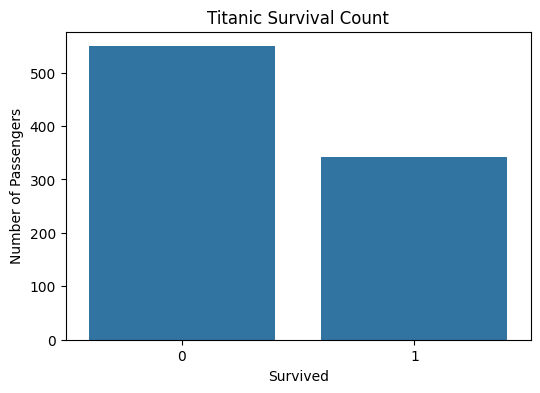

In [5]:
plt.figure(figsize=(6,4))

sns.countplot(data=df, x='Survived')

plt.title("Titanic Survival Count")
plt.xlabel("Survived")
plt.ylabel("Number of Passengers")

plt.show()

In [6]:
df = pd.get_dummies(
    df,
    columns=['Sex', 'Embarked'],
    drop_first=True,
    dtype=int
)

print(df.head())
print(df.info())

   PassengerId  Survived  Pclass  \
0            1         0       3   
1            2         1       1   
2            3         1       3   
3            4         1       1   
4            5         0       3   

                                                Name   Age  SibSp  Parch  \
0                            Braund, Mr. Owen Harris  22.0      1      0   
1  Cumings, Mrs. John Bradley (Florence Briggs Th...  38.0      1      0   
2                             Heikkinen, Miss. Laina  26.0      0      0   
3       Futrelle, Mrs. Jacques Heath (Lily May Peel)  35.0      1      0   
4                           Allen, Mr. William Henry  35.0      0      0   

             Ticket     Fare  Sex_male  Embarked_Q  Embarked_S  
0         A/5 21171   7.2500         1           0           1  
1          PC 17599  71.2833         0           0           0  
2  STON/O2. 3101282   7.9250         0           0           1  
3            113803  53.1000         0           0           1  
4

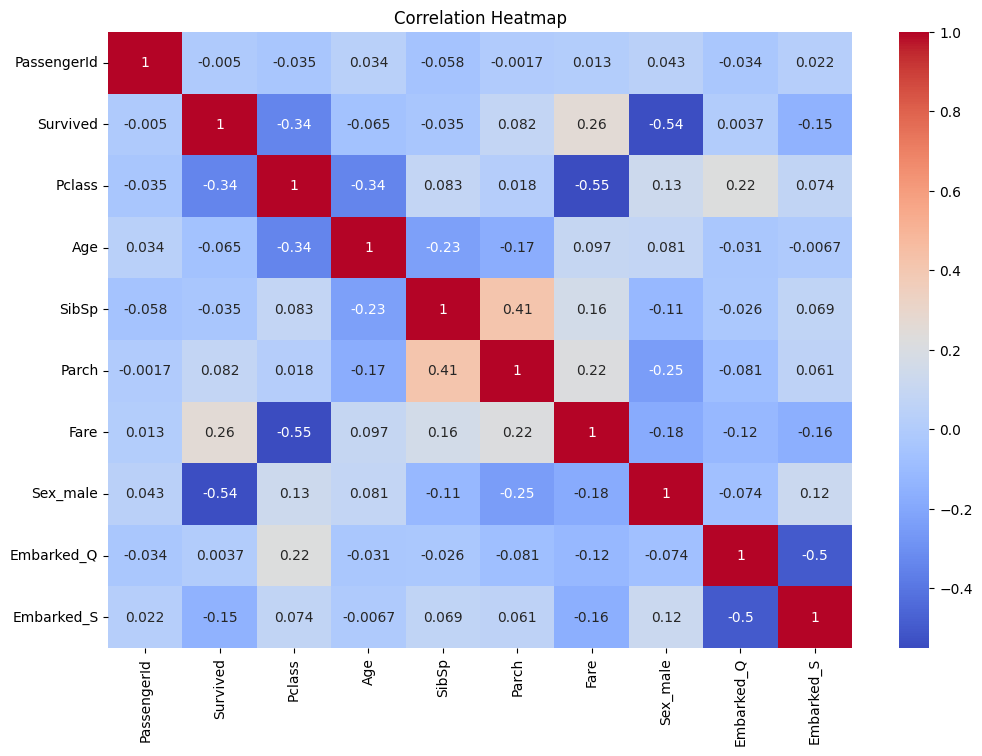

In [7]:
plt.figure(figsize=(12,8))

sns.heatmap(
    df.corr(numeric_only=True),
    annot=True,
    cmap='coolwarm'
)

plt.title("Correlation Heatmap")

plt.show()

In [5]:
from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline

# Features and Target
X = df.drop(
    ['Survived', 'PassengerId', 'Name', 'Ticket'],
    axis=1
)

y = df['Survived']

# Identify Columns
numeric_features = ['Age', 'SibSp', 'Parch', 'Fare', 'Pclass']
categorical_features = ['Sex', 'Embarked']

# Numerical Preprocessing
numeric_transformer = Pipeline([
    ('imputer', SimpleImputer(strategy='median')),
    ('scaler', StandardScaler())
])

# Categorical Preprocessing
categorical_transformer = Pipeline([
    ('imputer', SimpleImputer(strategy='most_frequent')),
    ('encoder', OneHotEncoder(handle_unknown='ignore'))
])

# Combine Preprocessing
preprocessor = ColumnTransformer([
    ('num', numeric_transformer, numeric_features),
    ('cat', categorical_transformer, categorical_features)
])

# Split Dataset
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("Training Data:", X_train.shape)
print("Testing Data:", X_test.shape)

Training Data: (712, 8)
Testing Data: (179, 8)


In [6]:
from sklearn.linear_model import LogisticRegression

model1 = Pipeline([
    ('preprocessing', preprocessor),
    ('model', LogisticRegression(max_iter=1000))
])

model1.fit(X_train, y_train)

pred1 = model1.predict(X_test)

print("Logistic Regression Training Completed")

Logistic Regression Training Completed


In [7]:
from sklearn.ensemble import RandomForestClassifier

model2 = Pipeline([
    ('preprocessing', preprocessor),
    ('model', RandomForestClassifier(
        n_estimators=100,
        random_state=42
    ))
])

model2.fit(X_train, y_train)

pred2 = model2.predict(X_test)

print("Random Forest Training Completed")

Random Forest Training Completed


In [8]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    confusion_matrix
)

def evaluate_model(name, y_test, predictions):

    print("\nModel:", name)

    print("Accuracy:",
          accuracy_score(y_test, predictions))

    print("Precision:",
          precision_score(y_test, predictions))

    print("Recall:",
          recall_score(y_test, predictions))

    print("F1 Score:",
          f1_score(y_test, predictions))

    print("\nClassification Report:")
    print(classification_report(y_test, predictions))


evaluate_model("Logistic Regression", y_test, pred1)

evaluate_model("Random Forest", y_test, pred2)


Model: Logistic Regression
Accuracy: 0.8044692737430168
Precision: 0.7931034482758621
Recall: 0.6666666666666666
F1 Score: 0.7244094488188977

Classification Report:
              precision    recall  f1-score   support

           0       0.81      0.89      0.85       110
           1       0.79      0.67      0.72        69

    accuracy                           0.80       179
   macro avg       0.80      0.78      0.79       179
weighted avg       0.80      0.80      0.80       179


Model: Random Forest
Accuracy: 0.8044692737430168
Precision: 0.7833333333333333
Recall: 0.6811594202898551
F1 Score: 0.7286821705426356

Classification Report:
              precision    recall  f1-score   support

           0       0.82      0.88      0.85       110
           1       0.78      0.68      0.73        69

    accuracy                           0.80       179
   macro avg       0.80      0.78      0.79       179
weighted avg       0.80      0.80      0.80       179



In [9]:
results = pd.DataFrame({
    'Model': ['Logistic Regression', 'Random Forest'],

    'Accuracy': [
        accuracy_score(y_test, pred1),
        accuracy_score(y_test, pred2)
    ],

    'Precision': [
        precision_score(y_test, pred1),
        precision_score(y_test, pred2)
    ],

    'Recall': [
        recall_score(y_test, pred1),
        recall_score(y_test, pred2)
    ],

    'F1 Score': [
        f1_score(y_test, pred1),
        f1_score(y_test, pred2)
    ]
})

print(results)

                 Model  Accuracy  Precision    Recall  F1 Score
0  Logistic Regression  0.804469   0.793103  0.666667  0.724409
1        Random Forest  0.804469   0.783333  0.681159  0.728682
